# PS 5C:
Object detection using Transfer Learning of CNN architectures for the Fashion
MNIST dataset using the below steps:
  
  a. Set up the environment
  
  b. Loading and preprocessing data
 
  c. Choose the pre-trained Model (Transfer Learning)
  
  d. Freeze the base layers and add custom layers for fine tuning
  
  e. Object detection training
  
  f. Compute loss
  
  g. Evaluate the Model
  
  h. Visualize the prediction
  
  i. Fine Tune the Model: Fine-tuning involves unfreezing the top layers of the pre-
trained model and retraining it on the new dataset to adapt it better to your task.

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Lambda, Dropout
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

In [2]:
# LOADING THE DATASET
DATA_DIR = "fashion mnist"
IMG_SIZE = (224, 224)

# loading training data (80%)
train_ds = keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split = 0.2,
    seed = 42,
    batch_size = 32,
    image_size = IMG_SIZE,
    subset = "training"
)

# loading testing data (20%)
test_ds = keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split = 0.2,
    seed = 42,
    subset = "validation",
    batch_size= 32,
    image_size = IMG_SIZE
)

Found 12832 files belonging to 11 classes.
Using 10266 files for training.
Found 12832 files belonging to 11 classes.
Using 2566 files for validation.


In [5]:
class_names = train_ds.class_names

print(len(class_names))
print(class_names)

11
['Ankle-boot', 'Bag', 'Coat', 'Dress', 'Pullover', 'Sandal', 'Shirt', 'Sneaker', 'T-shirt-top', 'Trouser', 'train']


In [12]:
# CHOOSING PRE-TRAINED BASE MODEL - VGG16
base_model = VGG16(
    weights = "imagenet",
    include_top = False,
    input_shape=(224, 224, 3)
)

In [15]:
# FREEZING THE BASE LAYER
base_model.trainable = False

# ADDING CUSTOM LAYER
model = Sequential([
    Lambda(preprocess_input),
    base_model,
    Flatten(),
    Dense(256, activation="relu"),
    Dropout(0.5),
    Dense(len(class_names), activation="sigmoid")
])

In [16]:
# COMPILE AND TRAIN THE MODEL
model.compile(
    optimizer = 'adam',
    loss = "sparse_categorical_crossentropy",
    metrics = ['accuracy']
)

history = model.fit(
    train_ds.take(10),
    validation_data = test_ds.take(10),
    epochs = 3
)

Epoch 1/3



C:\Users\ASUS\AppData\Roaming\Python\Python312\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


10/10 ━━━━━━━━━━━━━━━━━━━━ 296s 31s/step - accuracy: 0.2656 - loss: 21.1344 - val_accuracy: 0.3562 - val_loss: 9.4144
Epoch 2/3
10/10 ━━━━━━━━━━━━━━━━━━━━ 520s 53s/step - accuracy: 0.3375 - loss: 10.3140 - val_accuracy: 0.3781 - val_loss: 4.5353
Epoch 3/3
10/10 ━━━━━━━━━━━━━━━━━━━━ 292s 31s/step - accuracy: 0.3906 - loss: 5.0062 - val_accuracy: 0.3313 - val_loss: 4.2855


In [17]:
# COMPUTE AND EVALUATE MODEL
test_loss, test_accuracy = model.evaluate(test_ds.take(10))

print("Test loss: ", test_loss)
print("Test Accuracy: ", test_accuracy)

10/10 ━━━━━━━━━━━━━━━━━━━━ 142s 14s/step - accuracy: 0.3438 - loss: 3.8737
Test loss:  3.8737194538116455
Test Accuracy:  0.34375


1/1 ━━━━━━━━━━━━━━━━━━━━ 14s 14s/step


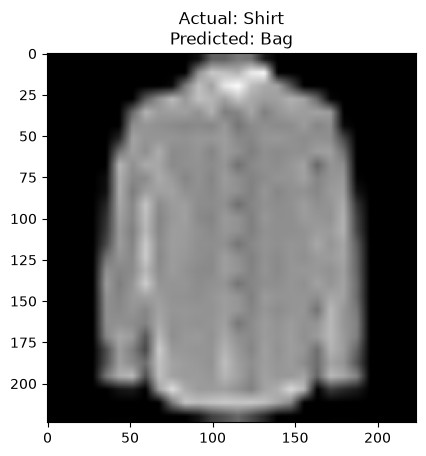

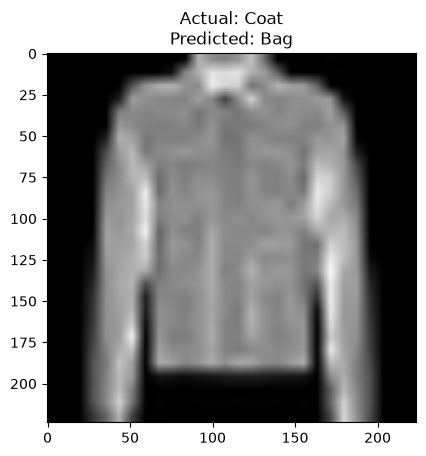

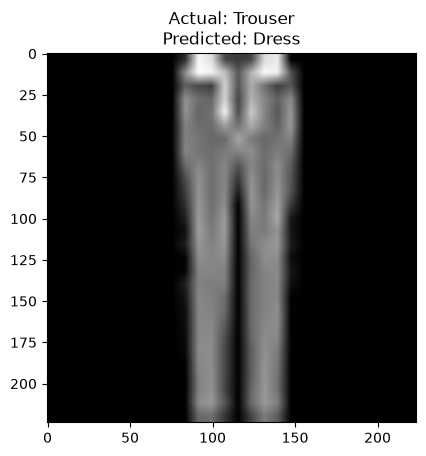

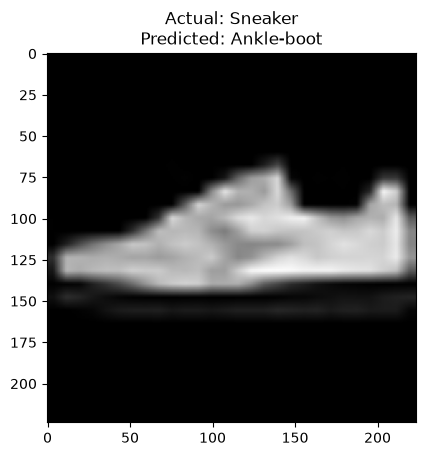

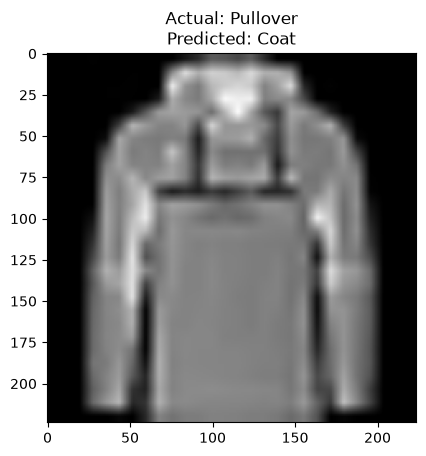

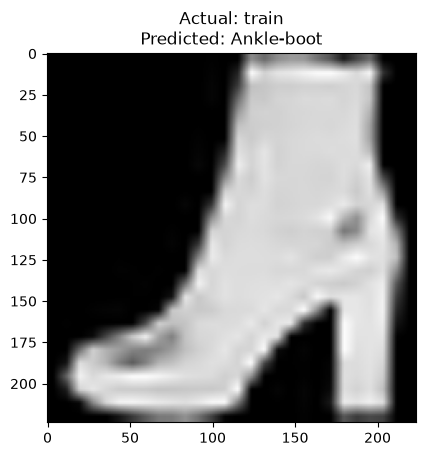

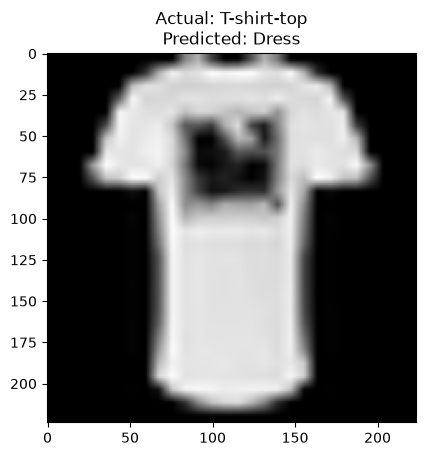

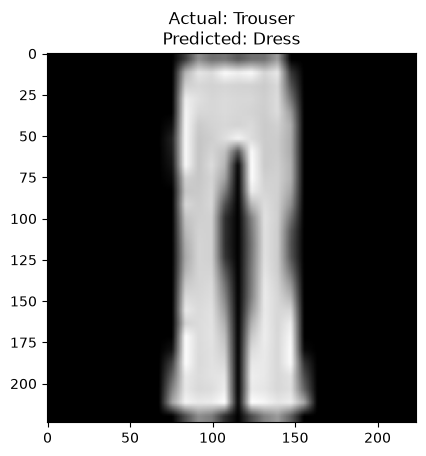

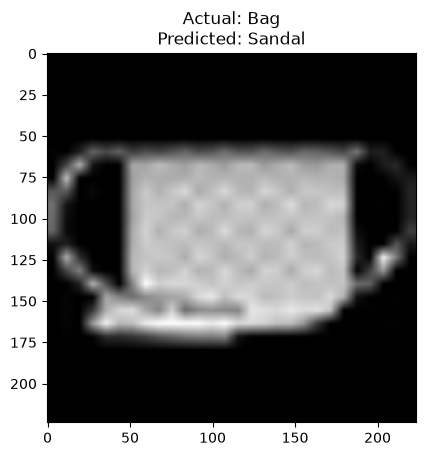

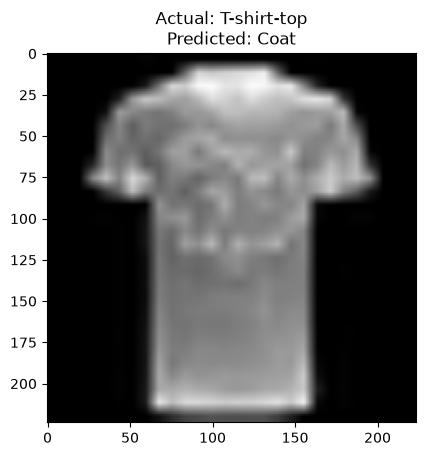

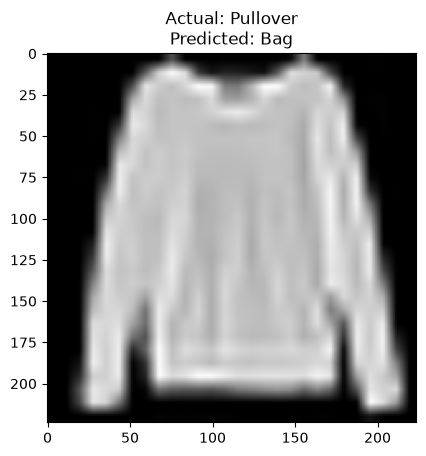

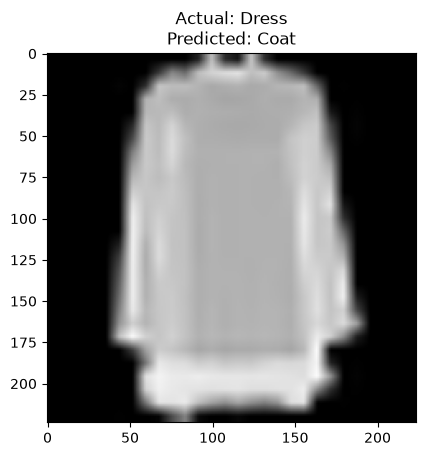

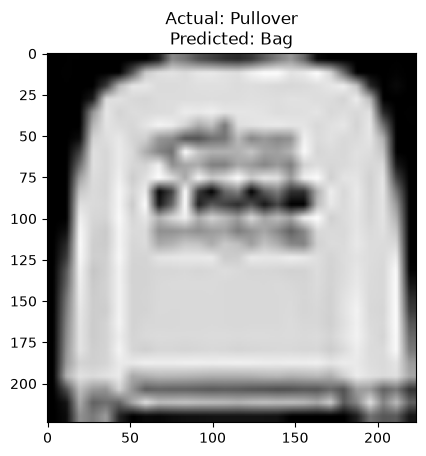

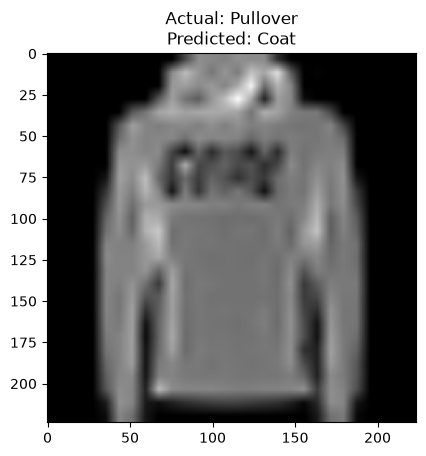

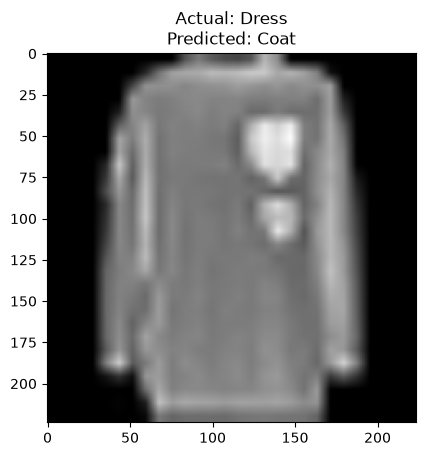

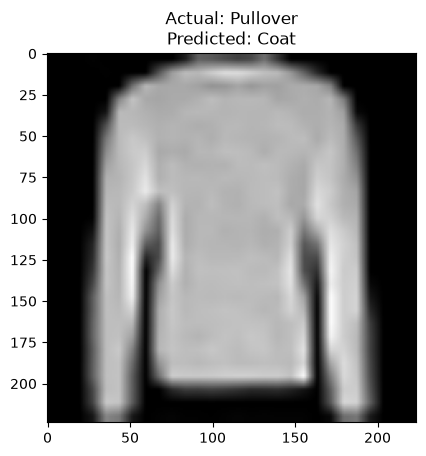

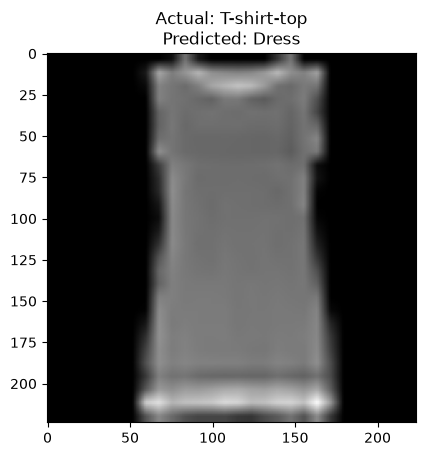

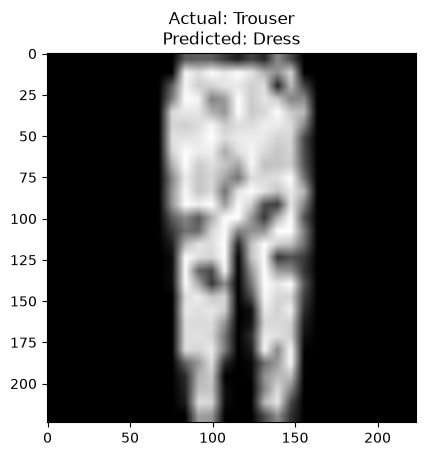

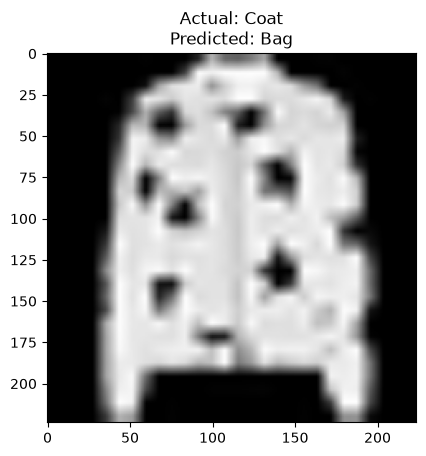

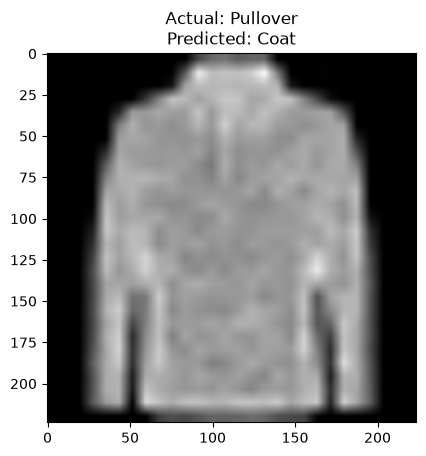

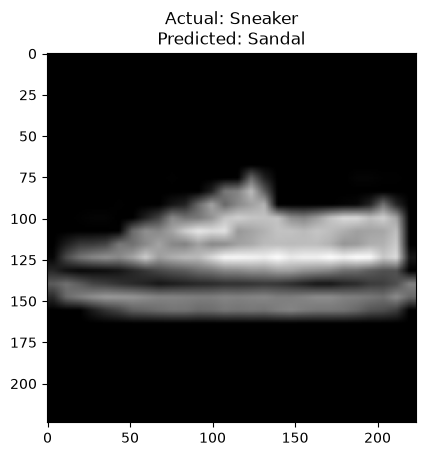

In [22]:
# VISUALIZE THE PREDICTIONS

for images, labels in test_ds.take(1):
    predictions = model.predict(images)

    for i in range(32):
        predicted = np.argmax(predictions[i])
        actual = int(labels[i].numpy())

        if ( class_names[actual] != class_names[predicted]):
            plt.imshow(images[i].numpy().astype("uint8"))
            plt.title("Actual: " + class_names[actual] + "\nPredicted: " + class_names[predicted])
            plt.show()

In [23]:
# FINE TUNE THE MODEL

# Unfreeze VGG16
base_model.trainable = True

# Freeze all layers except last 4
for layer in base_model.layers[:-4]:
    layer.trainable = False 

# Compile model
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.00001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train again
model.fit(
    train_ds.take(10),
    validation_data=test_ds.take(10),
    epochs=3,
    batch_size = 32
)

Epoch 1/3
10/10 ━━━━━━━━━━━━━━━━━━━━ 322s 34s/step - accuracy: 0.3812 - loss: 2.9070 - val_accuracy: 0.4875 - val_loss: 3.0849
Epoch 2/3
10/10 ━━━━━━━━━━━━━━━━━━━━ 319s 34s/step - accuracy: 0.4625 - loss: 1.6353 - val_accuracy: 0.5781 - val_loss: 2.0735
Epoch 3/3
10/10 ━━━━━━━━━━━━━━━━━━━━ 315s 33s/step - accuracy: 0.5594 - loss: 1.0465 - val_accuracy: 0.6219 - val_loss: 1.9267
